# 03 · Phân phối xác suất của lợi suất

Phạm vi: 20 mã HOSE (7 ngành), 2.118 phiên chung.

Câu hỏi: lợi suất có chuẩn không? Đuôi dày đến mức nào? Có hiện tượng biến động cụm không?

**Lưu ý quan trọng:** HOSE giới hạn biên độ ±7%/phiên nên lợi suất log ngày bị **chặn (censored)**:
biên trên $\ln(1{,}07) \approx 0{,}068$, biên dưới $\ln(0{,}93) \approx -0{,}073$ (lệch nhẹ do làm tròn
bước giá). Mọi ước lượng đuôi (Hill, CCDF) phải đọc với hạn chế này.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.4f}".format)
con = U.connect()
SYMBOLS = U.SYMBOLS
COL = U.SYMBOL_COLORS
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

SECTOR, SECTORS, SC = U.SECTOR, U.SECTORS, U.SECTOR_COLORS


def sector_style(ax, labels, axis="both", sep=True, fs=9):
    """Tô màu nhãn trục theo ngành và kẻ vạch phân cách ngành trên heatmap (nhãn theo thứ tự U.SYMBOLS)."""
    ticks = range(len(labels))
    if axis in ("both", "x"):
        ax.set_xticks(ticks, labels, rotation=90, fontsize=fs)
        for t, s in zip(ax.get_xticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if axis in ("both", "y"):
        ax.set_yticks(ticks, labels, fontsize=fs)
        for t, s in zip(ax.get_yticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if sep:
        cuts = [i - 0.5 for i in range(1, len(labels)) if SECTOR[labels[i]] != SECTOR[labels[i - 1]]]
        for c in cuts:
            ax.axhline(c, color="black", lw=0.8); ax.axvline(c, color="black", lw=0.8)


def big_heatmap(ax, matrix, fs_cell=6.5, annotate=True, **kw):
    """Heatmap 20x20: chữ trong ô nhỏ (hoặc bỏ), nhãn tô màu theo ngành, vạch phân cách ngành."""
    im = U.make_heatmap(ax, matrix, **kw)
    for t in list(ax.texts):
        if annotate: t.set_fontsize(fs_cell)
        else: t.remove()
    sector_style(ax, list(matrix.index))
    return im


def sector_legend(ax_or_fig, **kw):
    from matplotlib.patches import Patch
    h = [Patch(color=SC[s], label=s) for s in SECTORS]
    return ax_or_fig.legend(handles=h, **kw)

In [2]:
r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS]
print(r.shape)

(2120, 20)


## 1. Histogram so với phân phối chuẩn và Student-t

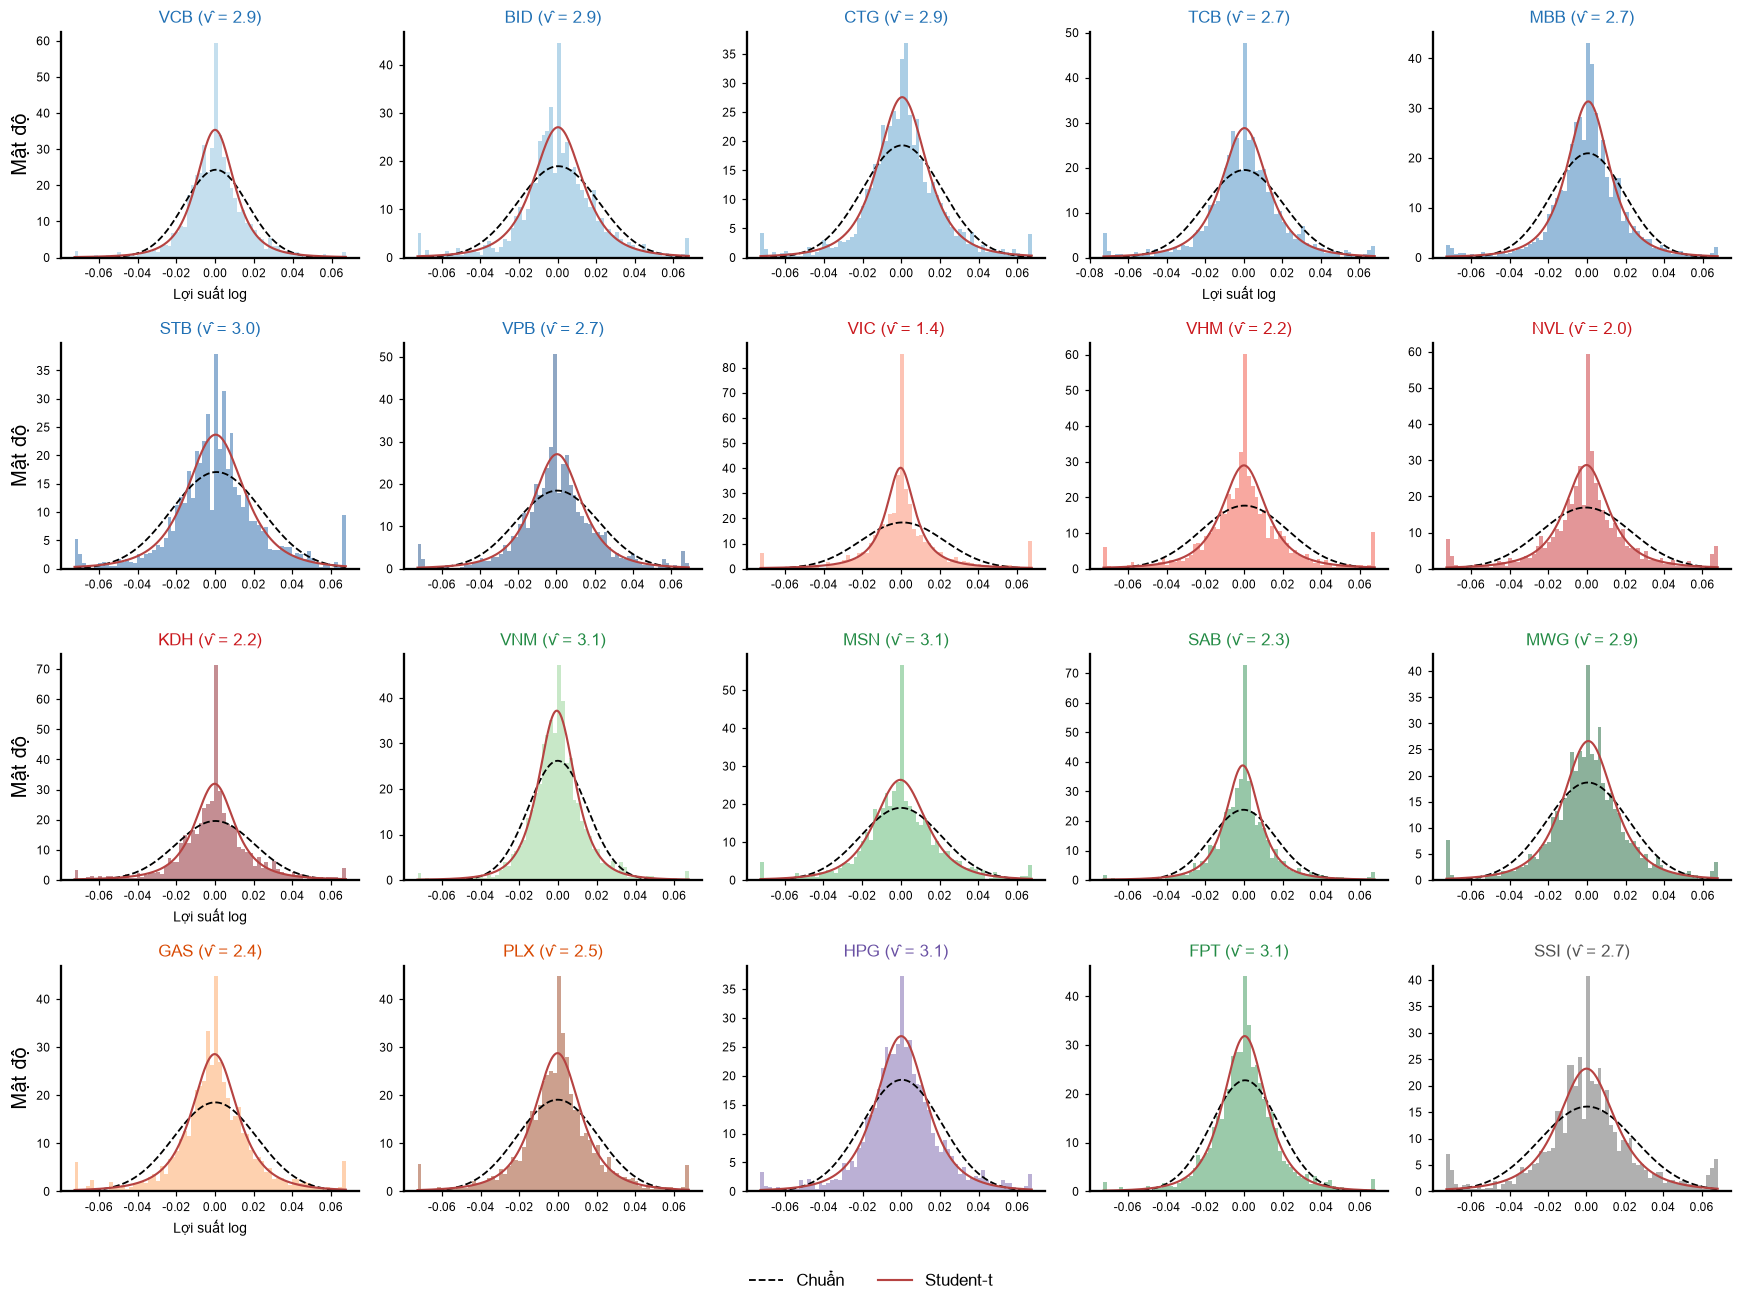

ν̂ Student-t: nhỏ nhất 1.44 | lớn nhất 3.13


In [3]:
fits = {}
fig, axes = plt.subplots(4, 5, figsize=(16, 11.5))
for ax, s in zip(axes.ravel(), SYMBOLS):
    x = r[s].dropna().values
    mu, sd = stats.norm.fit(x)
    df_t, loc_t, sc_t = stats.t.fit(x)
    fits[s] = (mu, sd, df_t, loc_t, sc_t)
    grid = np.linspace(x.min(), x.max(), 400)
    ax.hist(x, bins=70, density=True, color=COL[s], alpha=0.45, edgecolor="none")
    ax.plot(grid, stats.norm.pdf(grid, mu, sd), color="black", lw=1.2, ls="--", label="Chuẩn")
    ax.plot(grid, stats.t.pdf(grid, df_t, loc_t, sc_t), color=U.PALETTE["red_strong"], lw=1.4, label="Student-t")
    ax.set_title(f"{s} (ν̂ = {df_t:.1f})", fontsize=11, color=SC[SECTOR[s]])
    ax.tick_params(labelsize=8)
    if s in ("VCB", "TCB", "KDH", "GAS"): ax.set_xlabel("Lợi suất log", fontsize=9)
for ax in axes[:, 0]: ax.set_ylabel("Mật độ")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=11)
U.finalize_figure(fig, "03_hist_fit")
plt.show()
print("ν̂ Student-t: nhỏ nhất", min(v[2] for v in fits.values()).__round__(2), "| lớn nhất", max(v[2] for v in fits.values()).__round__(2))

## 2. Biểu đồ Q–Q so với phân phối chuẩn

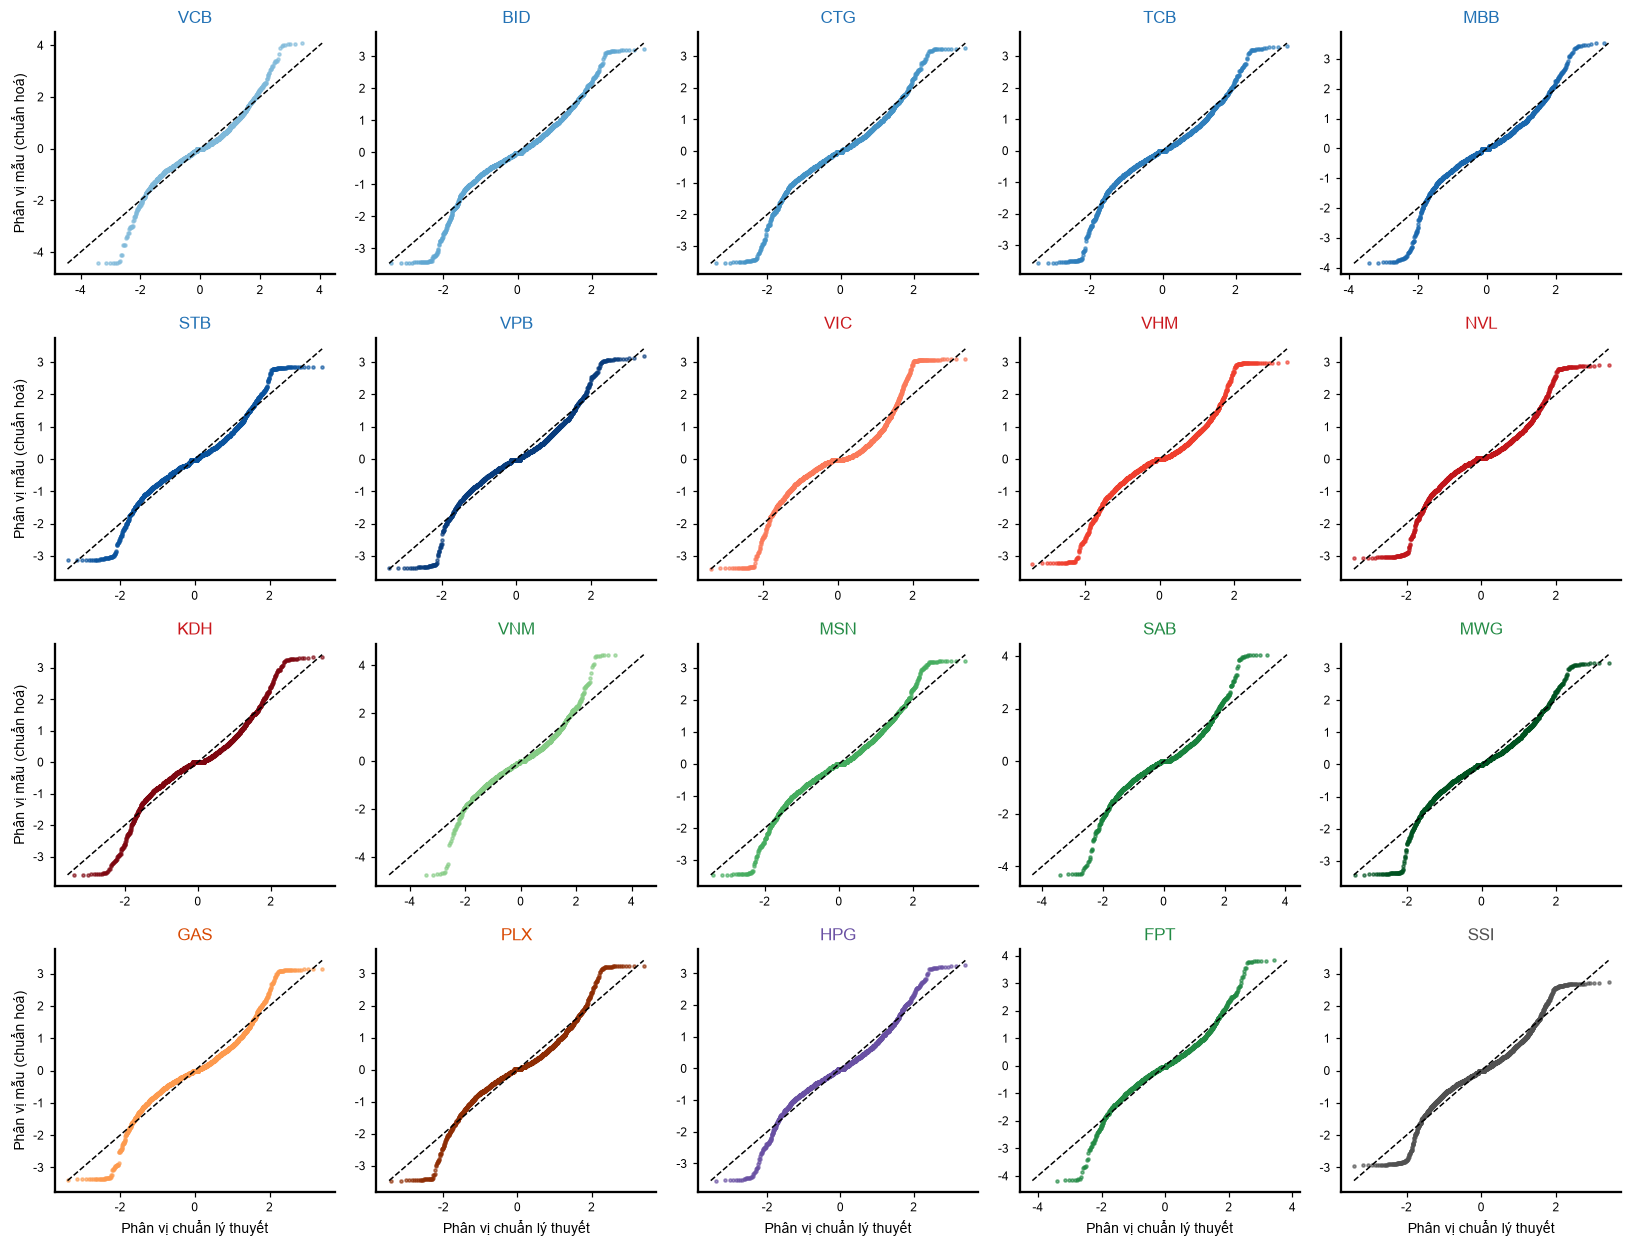

In [4]:
fig, axes = plt.subplots(4, 5, figsize=(15, 11.5))
for ax, s in zip(axes.ravel(), SYMBOLS):
    z = (r[s].dropna() - r[s].mean()) / r[s].std()
    (osm, osr), _ = stats.probplot(z, dist="norm")
    ax.scatter(osm, osr, s=4, color=COL[s], alpha=0.6)
    lim = [min(osm.min(), osr.min()), max(osm.max(), osr.max())]
    ax.plot(lim, lim, color="black", lw=1, ls="--")
    ax.set_title(s, fontsize=11, color=SC[SECTOR[s]])
    ax.tick_params(labelsize=8)
for ax in axes[-1]: ax.set_xlabel("Phân vị chuẩn lý thuyết", fontsize=9)
for ax in axes[:, 0]: ax.set_ylabel("Phân vị mẫu (chuẩn hoá)", fontsize=9)
U.finalize_figure(fig, "03_qq_normal")
plt.show()

## 3. Kiểm định tính chuẩn

In [5]:
rows = []
for s in SYMBOLS:
    x = r[s].dropna().values
    jb = stats.jarque_bera(x)
    sw = stats.shapiro(x)
    ad = stats.anderson(x, dist="norm")
    mu, sd, df_t, loc_t, sc_t = fits[s]
    rows.append({"symbol": s,
                 "JB": jb.statistic, "JB p": jb.pvalue,
                 "Shapiro W": sw.statistic, "Shapiro p": sw.pvalue,
                 "Anderson A²": ad.statistic, "AD crit 5%": ad.critical_values[2],
                 # truyền hàm CDF (scipy 1.18 lỗi khi dùng tên phân phối + args)
                 "KS (chuẩn) p": stats.kstest(x, lambda v: stats.norm.cdf(v, loc=mu, scale=sd)).pvalue,
                 "KS (t) p": stats.kstest(x, lambda v: stats.t.cdf(v, df_t, loc=loc_t, scale=sc_t)).pvalue})
normality = pd.DataFrame(rows).set_index("symbol")
print("Số mã bị bác bỏ tính chuẩn ở mức 1%:", {k: int((normality[c] < 0.01).sum()) for k, c in [("JB", "JB p"), ("Shapiro", "Shapiro p"), ("KS chuẩn", "KS (chuẩn) p")]},
      "| AD: A² > ngưỡng 5%:", int((normality["Anderson A²"] > normality["AD crit 5%"]).sum()), "| KS(t) p < 1%:", int((normality["KS (t) p"] < 0.01).sum()))
U.save_table(normality, "03_normality_tests")
normality

Số mã bị bác bỏ tính chuẩn ở mức 1%: {'JB': 20, 'Shapiro': 20, 'KS chuẩn': 20} | AD: A² > ngưỡng 5%: 20 | KS(t) p < 1%: 15


,JB,JB p,Shapiro W,Shapiro p,Anderson A²,AD crit 5%,KS (chuẩn) p,KS (t) p
symbol,,,,,,,,
VCB,969.6650,0.0000,0.9459,0.0000,29.5781,0.7520,0.0000,0.0001
BID,455.0959,0.0000,0.9530,0.0000,28.3958,0.7520,0.0000,0.0001
CTG,496.5318,0.0000,0.9526,0.0000,27.7116,0.7520,0.0000,0.0184
TCB,606.6620,0.0000,0.9460,0.0000,31.8827,0.7520,0.0000,0.0009
MBB,877.5280,0.0000,0.9389,0.0000,33.6904,0.7520,0.0000,0.0005
STB,233.8257,0.0000,0.9610,0.0000,25.1016,0.7520,0.0000,0.0072
VPB,465.0196,0.0000,0.9497,0.0000,30.8306,0.7520,0.0000,0.0001
VIC,790.7640,0.0000,0.9016,0.0000,76.1052,0.7520,0.0000,0.0000
VHM,438.8419,0.0000,0.9379,0.0000,44.6154,0.7520,0.0000,0.0001


## 4. So sánh các phân phối ứng viên (AIC/BIC)

In [6]:
candidates = {"Chuẩn": stats.norm, "Student-t": stats.t, "Laplace": stats.laplace,
              "Chuẩn lệch": stats.skewnorm, "Logistic": stats.logistic}
rows = []
for s in SYMBOLS:
    x = r[s].dropna().values
    n = len(x)
    for name, dist in candidates.items():
        params = dist.fit(x)
        ll = dist.logpdf(x, *params).sum()
        k = len(params)
        rows.append({"symbol": s, "phân phối": name, "logL": ll,
                     "AIC": 2 * k - 2 * ll, "BIC": k * np.log(n) - 2 * ll})
ic = pd.DataFrame(rows)
best = ic.loc[ic.groupby("symbol")["AIC"].idxmin(), ["symbol", "phân phối"]].set_index("symbol")
U.save_table(ic.set_index(["symbol", "phân phối"]), "03_distribution_ic")
display(ic.pivot(index="symbol", columns="phân phối", values="AIC").loc[SYMBOLS].round(1))
print("Số mã mà mỗi phân phối có AIC nhỏ nhất:", best["phân phối"].value_counts().to_dict())
best.rename(columns={"phân phối": "AIC nhỏ nhất"}).T

phân phối,Chuẩn,Chuẩn lệch,Laplace,Logistic,Student-t
symbol,,,,,
VCB,"-11,404.5000","-11,407.4000","-11,820.2000","-11,677.9000","-11,773.8000"
BID,"-10,351.8000","-10,369.6000","-10,696.0000","-10,575.6000","-10,652.6000"
CTG,"-10,426.2000","-10,441.1000","-10,777.6000","-10,657.8000","-10,738.0000"
TCB,"-10,453.0000","-10,475.0000","-10,853.7000","-10,708.5000","-10,811.8000"
MBB,"-10,772.8000","-10,801.6000","-11,208.3000","-11,061.0000","-11,178.9000"
STB,"-9,907.9000","-9,907.9000","-10,190.1000","-10,086.5000","-10,139.1000"
VPB,"-10,236.0000","-10,245.2000","-10,631.4000","-10,471.1000","-10,563.4000"
VIC,"-10,229.8000","-10,251.2000","-11,021.9000","-10,594.7000","-10,986.0000"
VHM,"-10,059.7000","-10,064.9000","-10,585.8000","-10,321.0000","-10,483.4000"


Số mã mà mỗi phân phối có AIC nhỏ nhất: {'Laplace': 20}


symbol,BID,CTG,FPT,GAS,HPG,KDH,MBB,MSN,MWG,NVL,PLX,SAB,SSI,STB,TCB,VCB,VHM,VIC,VNM,VPB
AIC nhỏ nhất,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace,Laplace


## 5. Đuôi phân phối: CCDF log–log và ước lượng Hill

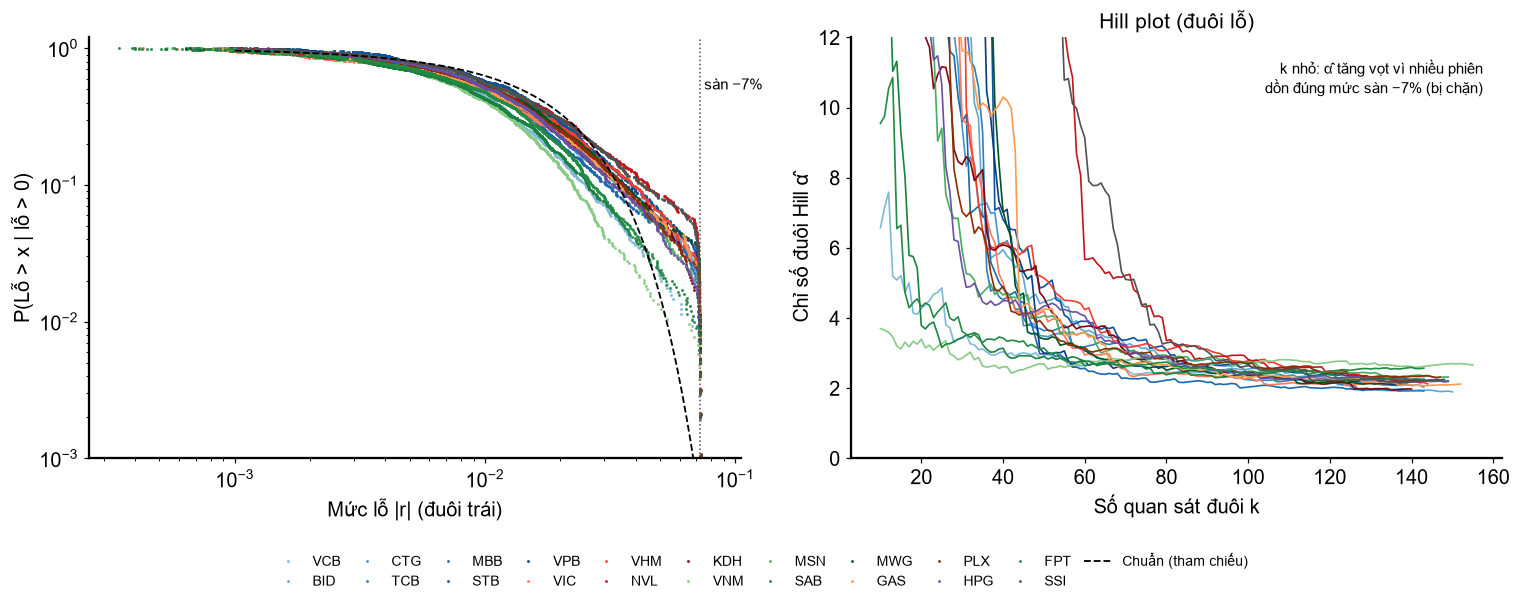

Hill α̂ — trung vị theo k: {'α̂ (k=25)': 21.11, 'α̂ (k=50)': 3.93, 'α̂ (k=100)': 2.47} | nhỏ nhất–lớn nhất ở k=100: 2.03 2.82


,α̂ (k=25),α̂ (k=50),α̂ (k=100)
VCB,4.8622,2.9211,2.3734
BID,19.6341,4.4543,2.5449
CTG,15.2421,3.4881,2.4151
TCB,63.2228,3.6408,2.2456
MBB,14.8983,2.9777,2.0349
STB,64.7418,4.8983,2.6856
VPB,60.3773,3.0016,2.4636
VIC,90.3756,4.1999,2.2846
VHM,58.1914,5.1409,2.7828
NVL,104.0849,28.6082,2.8213


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for s in SYMBOLS:
    loss = np.sort(-r[s].dropna().values)[::-1]
    loss = loss[loss > 0]
    ccdf = np.arange(1, len(loss) + 1) / len(loss)
    axes[0].loglog(loss, ccdf, ".", ms=2, color=COL[s], label=s, alpha=0.8)
z = np.logspace(-3, np.log10(0.08), 200)
sd_all = r.stack().std()
axes[0].loglog(z, stats.norm.sf(z, 0, sd_all) / 0.5, color="black", ls="--", lw=1.2, label="Chuẩn (tham chiếu)")
axes[0].axvline(0.0725, color=U.PALETTE["gray_dark"], lw=1, ls=":")
axes[0].text(0.0725, 0.5, " sàn −7%", fontsize=10)
axes[0].set_xlabel("Mức lỗ |r| (đuôi trái)")
axes[0].set_ylabel("P(Lỗ > x | lỗ > 0)")
axes[0].set_ylim(1e-3, 1.2)

def hill(x, kmax):
    xs = np.sort(x)[::-1]
    logs = np.log(xs)
    ks = np.arange(10, kmax)
    return ks, np.array([1 / (logs[:k].mean() - logs[k]) for k in ks])

hill_rows = {}
for s in SYMBOLS:
    loss = -r[s].dropna().values
    loss = loss[loss > 0]
    ks, alpha = hill(loss, int(0.15 * len(loss)))
    axes[1].plot(ks, alpha, color=COL[s], lw=1.1, label=s)
    hill_rows[s] = {f"α̂ (k={k})": alpha[ks == k][0] for k in (25, 50, 100)}
axes[1].set_ylim(0, 12)
axes[1].text(0.97, 0.95, "k nhỏ: α̂ tăng vọt vì nhiều phiên\ndồn đúng mức sàn −7% (bị chặn)",
             transform=axes[1].transAxes, ha="right", va="top", fontsize=10)
axes[1].set_xlabel("Số quan sát đuôi k")
axes[1].set_ylabel("Chỉ số đuôi Hill α̂")
axes[1].set_title("Hill plot (đuôi lỗ)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=11, fontsize=9, columnspacing=0.9)
U.finalize_figure(fig, "03_tail_ccdf_hill")
plt.show()

hill_tab = pd.DataFrame(hill_rows).T
U.save_table(hill_tab, "03_hill_tail_index")
print("Hill α̂ — trung vị theo k:", hill_tab.median().round(2).to_dict(), "| nhỏ nhất–lớn nhất ở k=100:",
      round(hill_tab["α̂ (k=100)"].min(), 2), round(hill_tab["α̂ (k=100)"].max(), 2))
hill_tab

In [8]:
# Mức độ "chặn" do biên độ: tỷ lệ phiên chạm trần/sàn trong khung phân tích
hits = con.execute("""
    SELECT symbol, AVG(hit_ceiling::INT) AS ty_le_tran, AVG(hit_floor::INT) AS ty_le_san
    FROM v_analysis GROUP BY symbol""").df().set_index("symbol").loc[SYMBOLS]
hits.insert(0, "ngành", [SECTOR[s] for s in hits.index])
hits

,ngành,ty_le_tran,ty_le_san
symbol,,,
VCB,Ngân hàng,0.0033,0.0038
BID,Ngân hàng,0.0094,0.0132
CTG,Ngân hàng,0.0080,0.0113
TCB,Ngân hàng,0.0085,0.0127
MBB,Ngân hàng,0.0057,0.0090
STB,Ngân hàng,0.0203,0.0160
VPB,Ngân hàng,0.0118,0.0160
VIC,Bất động sản,0.0222,0.0127
VHM,Bất động sản,0.0208,0.0142


## 6. Biến động cụm: ACF của $r_t$ và $|r_t|$, Ljung–Box, ARCH-LM

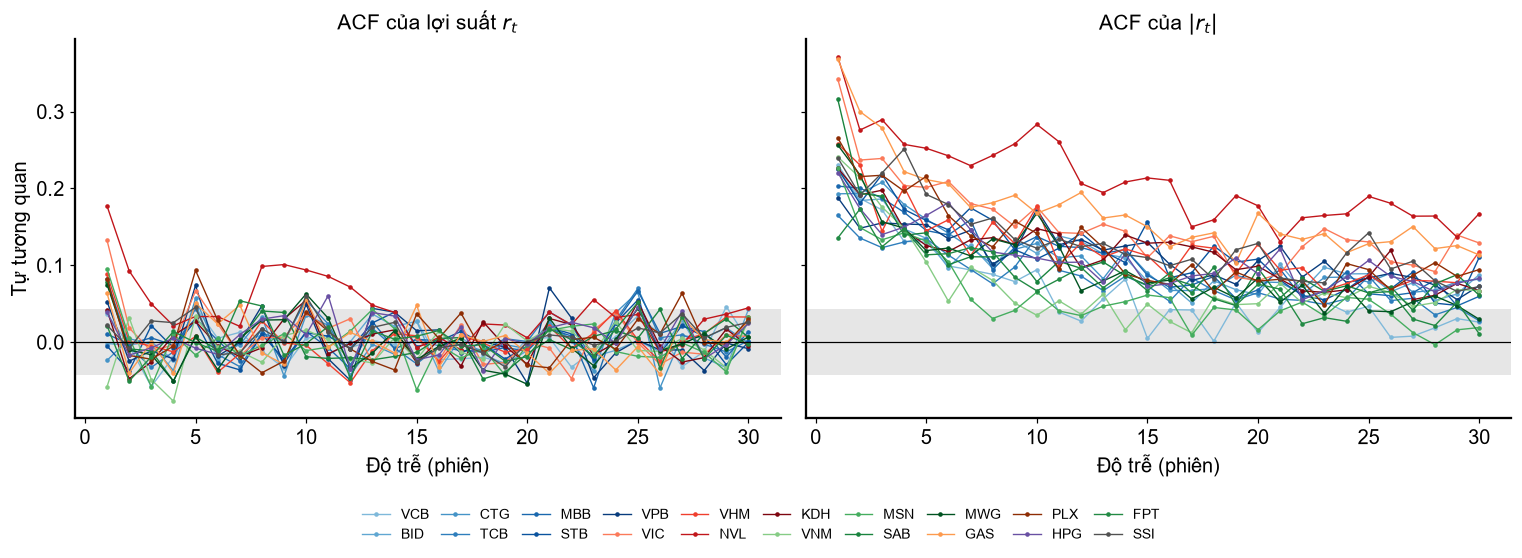

LB(10) của r có p < 5%: ['VCB', 'CTG', 'TCB', 'VPB', 'VIC', 'VHM', 'NVL', 'KDH', 'VNM', 'MSN', 'SAB', 'MWG', 'GAS', 'PLX', 'FPT']
LB(10) của r² có p < 1%: 20 / 20 | ARCH-LM p < 1%: 20 / 20


,LB(10) r p,LB(10) r² p,ARCH-LM(10) p,ρ̂(1) của |r|
symbol,,,,
VCB,0.0497,0.0000,0.0000,0.2308
BID,0.1506,0.0000,0.0000,0.2256
CTG,0.0256,0.0000,0.0000,0.1930
TCB,0.0008,0.0000,0.0000,0.1649
MBB,0.7802,0.0000,0.0000,0.2030
STB,0.3000,0.0000,0.0000,0.2254
VPB,0.0003,0.0000,0.0000,0.1882
VIC,0.0000,0.0000,0.0000,0.3422
VHM,0.0131,0.0000,0.0000,0.2579


In [9]:
LAGS = 30
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
band = 1.96 / np.sqrt(len(r))
acf_r, acf_a = {}, {}
for s in SYMBOLS:
    x = r[s].dropna()
    acf_r[s] = acf(x, nlags=LAGS)[1:]; acf_a[s] = acf(x.abs(), nlags=LAGS)[1:]
    axes[0].plot(range(1, LAGS + 1), acf_r[s], marker="o", ms=2, lw=0.9, color=COL[s], label=s)
    axes[1].plot(range(1, LAGS + 1), acf_a[s], marker="o", ms=2, lw=0.9, color=COL[s])
for ax, t in zip(axes, ["ACF của lợi suất $r_t$", "ACF của $|r_t|$"]):
    ax.axhspan(-band, band, color=U.PALETTE["neutral"], alpha=0.5, lw=0)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(t); ax.set_xlabel("Độ trễ (phiên)")
axes[0].set_ylabel("Tự tương quan")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=10, fontsize=9, columnspacing=0.9)
U.finalize_figure(fig, "03_acf_volatility_clustering")
plt.show()

rows = []
for s in SYMBOLS:
    x = r[s].dropna()
    rows.append({"symbol": s,
                 "LB(10) r p": acorr_ljungbox(x, lags=[10])["lb_pvalue"].iloc[0],
                 "LB(10) r² p": acorr_ljungbox(x**2, lags=[10])["lb_pvalue"].iloc[0],
                 "ARCH-LM(10) p": het_arch(x - x.mean(), nlags=10)[1],
                 "ρ̂(1) của |r|": acf_a[s][0]})
dep = pd.DataFrame(rows).set_index("symbol")
U.save_table(dep, "03_autocorr_arch_tests")
print("LB(10) của r có p < 5%:", [s for s in SYMBOLS if dep.loc[s, "LB(10) r p"] < 0.05])
print("LB(10) của r² có p < 1%:", int((dep["LB(10) r² p"] < 0.01).sum()), "/ 20 | ARCH-LM p < 1%:", int((dep["ARCH-LM(10) p"] < 0.01).sum()), "/ 20")
dep

## 7. Nhận xét

(20 mã, 2.118 phiên chung.)

- **Không chuẩn:** JB, Shapiro–Wilk, Anderson–Darling và KS (so với chuẩn) đều bác bỏ tính chuẩn ở **cả 20/20 mã** (p ≈ 0 ở mức 1%; JB từ 211 ở SSI đến 1.354 ở SAB).
  Q–Q plot cong ở hai đầu rồi **gãy phẳng** ở các mức ~±2,8σ đến ±4σ tuỳ mã — dấu vết của biên độ ±7%. Mã có biến động thấp như VNM, SAB, VCB, FPT gãy ở xa hơn (≈ ±4σ)
  vì biên ±7% là mức cực đoan so với độ lệch chuẩn nhỏ của chúng; mã biến động cao như SSI, VIC, NVL gãy sớm hơn (≈ ±2,8–3σ).
- **Phân phối phù hợp hơn:** theo AIC, **Laplace tốt nhất ở 20/20 mã**, Student-t xếp thứ hai; KS vẫn bác bỏ Student-t ở mức 1% với 15/20 mã (không bác bỏ ở MWG, FPT, VNM, CTG, GAS). Bậc tự do ước lượng
  ν̂ nằm trong 1,4–3,1: thấp nhất VIC (1,4), NVL, KDH, VHM, SAB (2,0–2,2), cao nhất FPT, VNM, MSN (≈ 3,1). **Hạn chế:** 5,6–12,5% số phiên có lợi suất đúng bằng 0 (bước giá rời rạc) — khối
  xác suất tại 0 khiến KS so với phân phối liên tục gần như chắc chắn bác bỏ, và một phần lợi thế AIC của Laplace đến từ đỉnh nhọn ở 0. ν̂ < 2 ở VIC cho thấy Student-t bị kéo bởi khối tại 0 và các điểm dồn ở biên, không nên đọc như chỉ số đuôi thật.
  Cần mô hình hỗn hợp (khối tại 0 + phân phối liên tục) nếu muốn khớp chính xác.
- **Đuôi:** CCDF nằm trên đường chuẩn trong vùng lỗ ~3–7% (đuôi dày) nhưng rơi thẳng đứng tại sàn. Tỷ lệ phiên chạm sàn từ 0,33% (VNM) đến 2,45% (NVL), chạm trần từ 0,28% (VNM) đến 2,31% (SSI);
  nhóm bất động sản (VIC, VHM, NVL) và SSI, STB chạm biên nhiều nhất, VNM, VCB, SAB, FPT ít nhất → mức độ bị chặn **rất khác nhau giữa các mã** (chênh nhau tới 8 lần).
  Hill α̂ giảm dần theo k: ở k = 25 vọt lên tới hàng chục–hàng trăm (trung vị 21; NVL 104, MWG 137) vì nhiều phiên dồn đúng mức sàn; ở k = 50 trung vị 3,9 (NVL, SSI vẫn ~28); chỉ từ k ≈ 80–100 các đường mới hội tụ vào vùng
  2–3 (k = 100: 2,03–2,82, trung vị 2,47). Vùng "ổn định" này nằm ở k lớn, tức đã lẫn cả phần thân phân phối, nên α̂ ≈ 2,5 **không thể diễn giải trực tiếp** là chỉ số đuôi; Hill không đáng tin trên dữ liệu bị chặn,
  cần mô hình đuôi có kiểm duyệt (censored EVT) hoặc lợi suất tần suất thấp hơn (tuần).
- **Biến động cụm:** ACF của $|r_t|$ dương suốt 30 lag khảo sát, $\hat\rho(1)$ của $|r_t|$ từ 0,14 (FPT) đến 0,37 (NVL; cao ở NVL, GAS, VIC, SAB ≥ 0,32); Ljung–Box trên $r_t^2$ và ARCH-LM có p ≈ 0 ở **20/20 mã**.
  Tự tương quan của chính $r_t$ yếu hơn và không đồng đều: Ljung–Box(10) có p < 5% ở 15/20 mã (p < 0,001 ở TCB, VPB, VIC, NVL, VNM, MWG, GAS, PLX), không có ý nghĩa ở BID, MBB, STB, HPG, SSI (VCB sát ngưỡng, p = 0,0497).